# Tapered beams

In [1]:
import xara
import numpy as np
from xara.helpers import find_node

In [2]:
P = 1
E = 1
a = -0.1
b = 40
L = 10

Ix = lambda x: np.pi/4.0*(a*x + b)**4

c1 = (2.*L*a - b)/(6*b**3)
c2 = -(c1*b + (L*a+b)/(6.0*b**2) - 1.0/(2.0*b))

wx = lambda x: (4.*P/(np.pi*E*a**3))*(
    (L*a+b)/(6.0*(a*x+b)**2)
    - 1.0/(2.0*(a*x+b))
    + c1*(a*x+b)
    + c2
)

## Model 1: Prismatic Element

In [7]:
def create_model_v1(n, Ix, L):
    model = xara.Model(ndm=3, ndf=6)
    for i,x in enumerate(np.linspace(0, L, n)):
        model.node(i+1, (x, 0.0, 0.0))

    model.fix(1, (1, 1, 1, 1, 1, 1))
    
    # add elements
    model.geomTransf("Linear", 1, (0, 0, 1))
    for i in range(1, n):
        xi = model.nodeCoord(i, 1)
        xj = model.nodeCoord(i+1, 1)
        I = Ix(0.5*(xi + xj))
        model.element("ElasticFrame", i, 
                      (i, i+1), 
                      shear=0,
                      transform=1,
                      section=xara.FrameSection("Elastic", E=E, A=1.0, Iy=I, Iz=I, J=I*2, G=1)
        )
    
    tip = find_node(model, x=L)
    loads = xara.NodalLoad(model, {tip: (0, 0, P, 0, 0, 0)})
    model.pattern(xara.StaticPattern(loads))

    # Analysis
    xara.StaticAnalysis(model).analyze()
    return model

## Model 2: Section Integration

For elements that support specified quadrature rules, tapering can be modeled with a single element. 
The following uses a {ref}`UserDefined-BeamIntegration` beam integration to this end.

In [4]:
def create_model_v2(n, Ix, L):
    model = xara.Model(ndm=3, ndf=6)
    model.node(1, (0.0, 0.0, 0.0))
    model.node(2, ( L , 0.0, 0.0))

    model.fix(1, (1, 1, 1, 1, 1, 1))
    
    # add elements
    model.geomTransf("Linear", 1, (0, 0, 1))

    locs = [] #(0.1, 0.3 , 0.5, 0.7 , 0.9)
    wts  = [] #(0.2, 0.15, 0.3, 0.15, 0.2)
    secs = []
    for i in range(n):
        x = (i + 0.5) * L / n
        I = Ix(x)
        locs.append(x/L)
        wts.append(1.0/n)
        secs.append(xara.FrameSection("Elastic", E=E, A=1.0, Iy=I, Iz=I, J=I*2, G=1))

    model.beamIntegration("UserDefined",1, 
                          len(secs), tuple(secs), tuple(locs), tuple(wts))

    transform = 1
    integration = 1
    model.element("ForceFrame", 1, 
                    (1, 2), 
                    transform,
                    integration,
                    shear=0,
    )
    
    tip = find_node(model, x=L)
    loads = xara.NodalLoad(model, {tip: (0, 0, P, 0, 0, 0)})
    model.pattern(xara.StaticPattern(loads))

    # Analysis
    xara.StaticAnalysis(model).analyze()
    return model

## Results

In [5]:
assert all(Ix(np.linspace(0,L,10)) > 0)

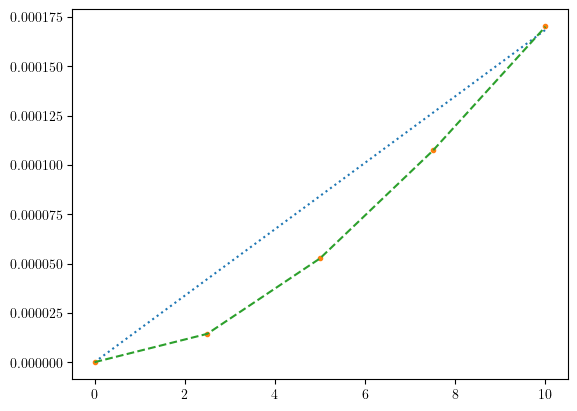

In [6]:

import matplotlib.pyplot as plt
fig, ax = plt.subplots()


model = create_model_v2(5, Ix, L)
x = np.array([model.nodeCoord(i, 1) for i in model.getNodeTags()])
y = [model.nodeDisp(i, 3)  for i in model.getNodeTags()]
ax.plot(x, y, ":")

model = create_model_v1(5, Ix, L)
x = np.array([model.nodeCoord(i, 1) for i in model.getNodeTags()])
y = [model.nodeDisp(i, 3)  for i in model.getNodeTags()]
ax.plot(x, y, ".")


ax.plot(x, wx(x), ls="--")